# 01 · Exploratory Data Analysis
E-commerce churn project: explore the cleaned PostgreSQL data before modelling.

**Questions:** How is the business trending? Who are the customers? Which behaviours differ between customers who churn and those who stay?

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sqlalchemy import text
from src.config import get_engine, SNAPSHOT_DATE
engine = get_engine()
sns.set_theme(style="whitegrid", palette=["#2a78d6", "#eb6834", "#1baf7a"])
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Data overview

In [2]:
tables = ["customers", "products", "orders", "order_items", "support_tickets", "web_sessions"]
pd.DataFrame({t: pd.read_sql(f"SELECT COUNT(*) AS n FROM {t}", engine)["n"] for t in tables}).T.rename(columns={0: "rows"})

,rows
customers,10000
products,500
orders,74060
order_items,125210
support_tickets,7361
web_sessions,111764


In [3]:
orders = pd.read_sql("SELECT * FROM v_orders", engine, parse_dates=["order_date"])
orders.describe(include="all").T.head(12)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,"74,060.00",NaN,NaN,NaN,"137,030.50","100,001.00","118,515.75","137,030.50","155,545.25","174,060.00","21,379.42"
customer_id,"74,060.00",NaN,NaN,NaN,"4,973.13",1.00,"2,443.00","4,896.00","7,562.00","10,000.00","2,910.51"
order_date,74060,NaN,NaN,NaN,2025-11-09 05:46:54.863624192,2024-01-03 00:00:00,2025-06-09 00:00:00,2025-12-08 00:00:00,2026-05-23 00:00:00,2026-09-30 00:00:00,NaN
status,74060,3,Delivered,65283,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,74060,5,UPI,31147,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipping_days,"73,838.00",NaN,NaN,NaN,4.39,1.00,3.00,4.00,5.00,20.00,2.54
discount_pct,"74,060.00",NaN,NaN,NaN,7.79,0.00,0.00,5.00,15.00,30.00,8.50
order_value,"74,060.00",NaN,NaN,NaN,"4,154.55",37.80,577.60,"1,472.40","3,660.30","180,774.00","9,324.33"
order_margin,"74,060.00",NaN,NaN,NaN,"1,117.12","-4,594.47",130.09,348.97,947.47,"55,574.34","2,752.87"
units,"74,060.00",NaN,NaN,NaN,2.18,1.00,1.00,2.00,3.00,16.00,1.38


## 2. Business trend

/var/folders/z5/wngk1bk57nndzxhvtscb2k0c0000gn/T/ipykernel_6238/2849597025.py:5: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/nagasunojr/anaconda3/lib/python3.13/site-packages/IPython/core/events.py:82: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  func(*args, **kwargs)
/Users/nagasunojr/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


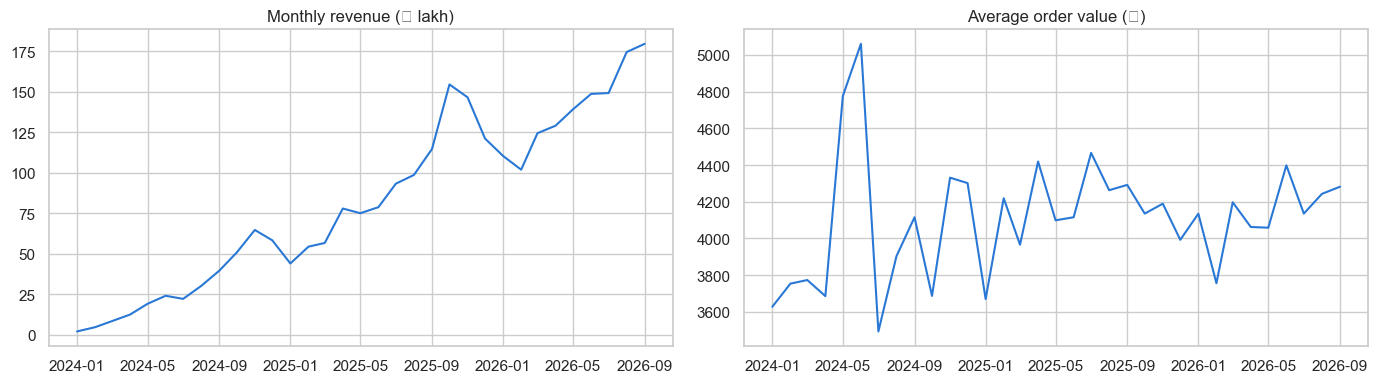

In [4]:
kpi = pd.read_sql("SELECT * FROM v_monthly_kpis ORDER BY month", engine, parse_dates=["month"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(kpi["month"], kpi["revenue"] / 1e5); axes[0].set_title("Monthly revenue (₹ lakh)")
axes[1].plot(kpi["month"], kpi["avg_order_value"]); axes[1].set_title("Average order value (₹)")
plt.tight_layout()

In [5]:
kpi[["month", "orders", "active_customers", "new_customers", "revenue", "revenue_mom_pct"]].tail(12)

,month,orders,active_customers,new_customers,revenue,revenue_mom_pct
21,2025-10-01,4241,2269,375,"15,462,439.00",34.74
22,2025-11-01,3973,2235,383,"14,671,313.15",-5.12
23,2025-12-01,3429,2055,384,"12,122,211.15",-17.37
24,2026-01-01,3025,1944,432,"11,044,523.90",-8.89
25,2026-02-01,3094,1990,421,"10,198,054.45",-7.66
26,2026-03-01,3353,2135,412,"12,452,188.20",22.10
27,2026-04-01,3610,2300,417,"12,914,915.55",3.72
28,2026-05-01,3895,2473,448,"13,929,478.15",7.86
29,2026-06-01,3825,2487,437,"14,878,998.50",6.82
30,2026-07-01,4132,2648,464,"14,932,785.85",0.36


## 3. Customer profile

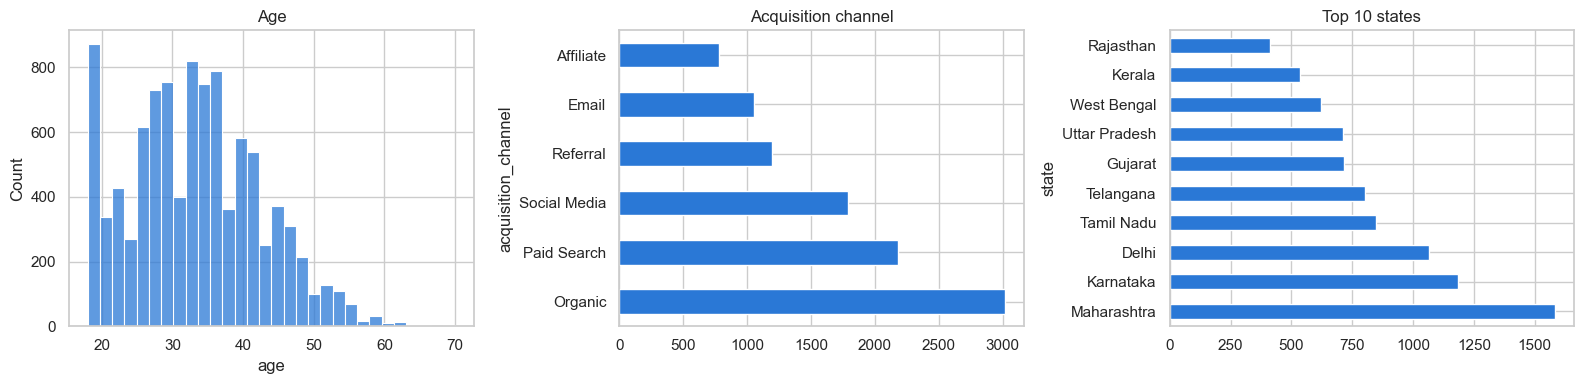

In [6]:
cust = pd.read_sql("SELECT * FROM customers", engine)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(cust["age"].dropna(), bins=30, ax=axes[0]).set_title("Age")
cust["acquisition_channel"].value_counts().plot.barh(ax=axes[1], title="Acquisition channel")
cust["state"].value_counts().head(10).plot.barh(ax=axes[2], title="Top 10 states")
plt.tight_layout()

## 4. Churned vs retained customers
Features from the `customer_features` SQL view at the training snapshot.

In [7]:
with engine.begin() as c:
    c.execute(text("UPDATE feature_params SET snap = :s"), {"s": SNAPSHOT_DATE})
    feat = pd.read_sql("SELECT * FROM customer_features", c)
print(f"{len(feat):,} active customers, churn rate {feat['churned'].mean():.1%}")
cols = ["recency_days", "frequency_365d", "orders_last_90d", "monetary_365d", "avg_shipping_days",
        "late_delivery_rate", "return_rate", "avg_satisfaction", "sessions_last_90d", "avg_session_minutes"]
feat.groupby("churned")[cols].mean().T.assign(diff_pct=lambda d: (d[True] / d[False] - 1) * 100)

6,571 active customers, churn rate 43.8%


churned,False,True,diff_pct
recency_days,45.90,138.99,202.85
frequency_365d,7.26,4.33,-40.31
orders_last_90d,2.36,0.75,-68.13
monetary_365d,"27,595.05","16,151.12",-41.47
avg_shipping_days,4.34,4.67,7.62
late_delivery_rate,0.09,0.13,50.69
return_rate,0.08,0.11,39.06
avg_satisfaction,3.20,2.99,-6.56
sessions_last_90d,8.70,3.25,-62.70
avg_session_minutes,6.20,4.18,-32.57


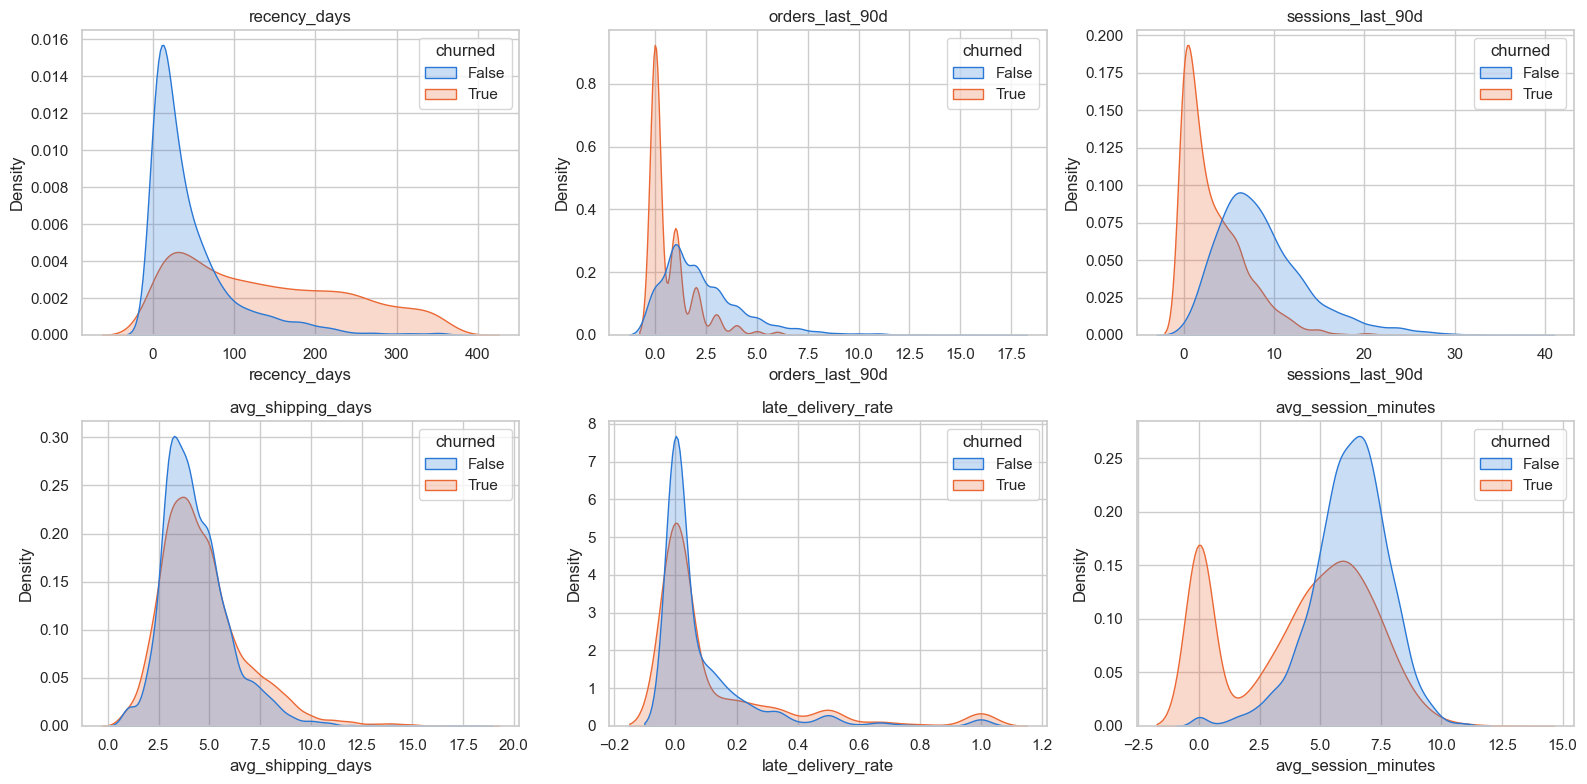

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, ["recency_days", "orders_last_90d", "sessions_last_90d",
                               "avg_shipping_days", "late_delivery_rate", "avg_session_minutes"]):
    sns.kdeplot(data=feat, x=col, hue="churned", common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()

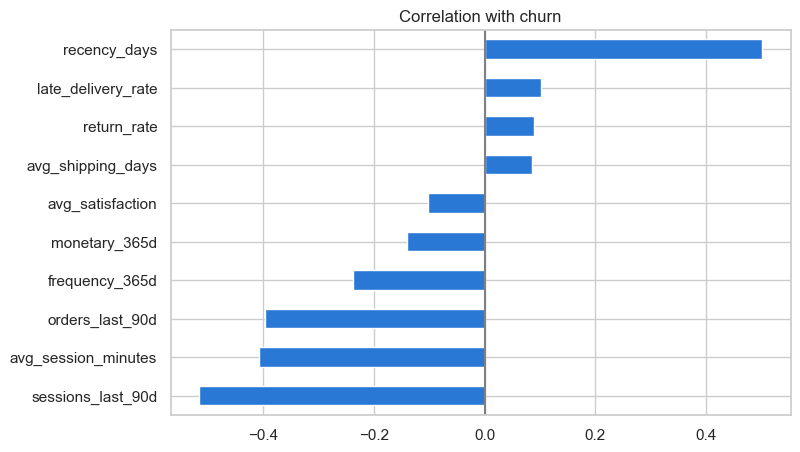

In [9]:
corr = feat[cols + ["churned"]].astype(float).corr()["churned"].drop("churned").sort_values()
corr.plot.barh(figsize=(8, 5), title="Correlation with churn"); plt.axvline(0, color="grey")

## Key takeaways
- Revenue grows strongly with festive peaks (Oct–Nov); Electronics dominates revenue.
- Churners have **fewer recent orders and web sessions**, **longer recency**, **slower deliveries** and **lower support satisfaction**.
- Social Media and Affiliate customers churn most; Referral customers least.
- These signals justify the engineered features used in `02_modeling.ipynb`.